In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean/superstore_clean.csv", dtype={"postal_code": str})
print(df.shape)   # expect (10194, 26)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
os.makedirs("../docs/images", exist_ok=True)

def style(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("#cfcfca")
    ax.spines["bottom"].set_color("#cfcfca")
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color="#e8e8e4", linewidth=0.8)
    ax.set_axisbelow(True)

(10194, 26)


discount_band
0%        29.56
1-10%     16.56
11-20%    11.54
21-30%   -10.06
31-40%   -19.45
>40%     -77.37
Name: margin, dtype: float64


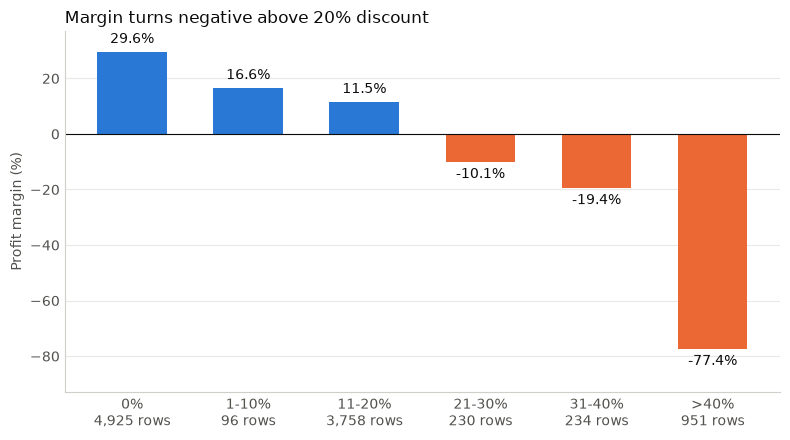

In [6]:
order = ["0%", "1-10%", "11-20%", "21-30%", "31-40%", ">40%"]
band = (df.groupby("discount_band")
          .agg(rows=("row_id", "count"), sales=("sales", "sum"), profit=("profit", "sum"))
          .reindex(order))
band["margin"] = band["profit"] / band["sales"] * 100
print(band["margin"].round(2))   # must match your SQL discount-band result

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(range(len(band)), band["margin"], width=0.6,
              color=[BLUE if m >= 0 else ORANGE for m in band["margin"]])
ax.axhline(0, color=INK, linewidth=0.8)
ax.set_xticks(range(len(band)))
ax.set_xticklabels([f"{b}\n{int(r):,} rows" for b, r in zip(band.index, band["rows"])])
for rect, m in zip(bars, band["margin"]):
    ax.annotate(f"{m:.1f}%", (rect.get_x() + rect.get_width() / 2, m),
                xytext=(0, 4 if m >= 0 else -4), textcoords="offset points",
                ha="center", va="bottom" if m >= 0 else "top", color=INK)
ax.set_ylabel("Profit margin (%)", color=MUTED)
ax.set_title("Margin turns negative above 20% discount", loc="left", color=INK)
style(ax)
ax.set_ylim(band["margin"].min() * 1.2, band["margin"].max() * 1.25)
plt.tight_layout()
plt.savefig("../docs/images/margin_by_discount_band.png", dpi=200)
plt.show()

group         High (>20%)  Low (0-20%)
sub_category                          
Binders           -106.54        40.89
Machines           -38.46        29.20
Tables             -33.96        11.11
Bookcases          -39.37         8.84


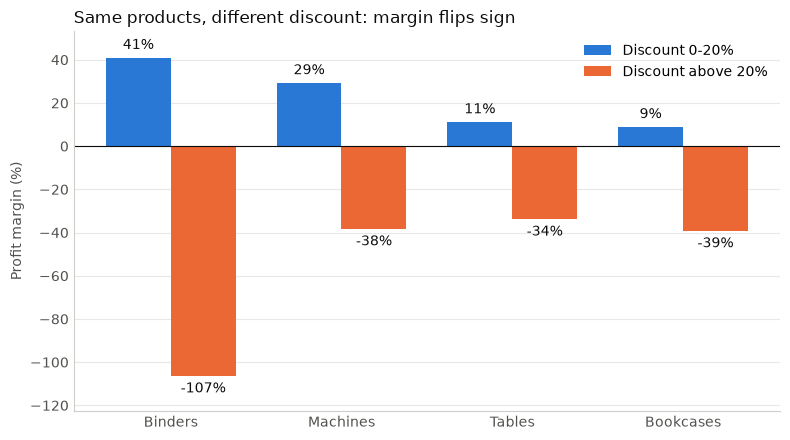

In [7]:
subs = ["Binders", "Machines", "Tables", "Bookcases"]
d = df[df["sub_category"].isin(subs)].copy()
d["group"] = np.where(d["discount"] > 0.20, "High (>20%)", "Low (0-20%)")
g = d.groupby(["sub_category", "group"]).agg(sales=("sales", "sum"), profit=("profit", "sum"))
g["margin"] = g["profit"] / g["sales"] * 100
m = g["margin"].unstack("group").loc[subs]
print(m.round(2))   # must match SQL Query 06

x = np.arange(len(subs)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
low = ax.bar(x - w/2, m["Low (0-20%)"], w, color=BLUE, label="Discount 0-20%")
high = ax.bar(x + w/2, m["High (>20%)"], w, color=ORANGE, label="Discount above 20%")
ax.axhline(0, color=INK, linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(subs)
for bars in (low, high):
    for r in bars:
        v = r.get_height()
        ax.annotate(f"{v:.0f}%", (r.get_x() + r.get_width() / 2, v),
                    xytext=(0, 4 if v >= 0 else -4), textcoords="offset points",
                    ha="center", va="bottom" if v >= 0 else "top", color=INK)
ax.set_ylabel("Profit margin (%)", color=MUTED)
ax.set_title("Same products, different discount: margin flips sign", loc="left", color=INK)
ax.legend(frameon=False)
style(ax)
ax.set_ylim(m.min().min() * 1.15, m.max().max() * 1.3)
plt.tight_layout()
plt.savefig("../docs/images/margin_low_vs_high_discount.png", dpi=200)
plt.show()

                  sales    profit  margin
sub_category                             
Tables        208020.18 -17753.21   -8.53
Bookcases     115361.20  -3632.07   -3.15
Supplies       46725.50  -1171.39   -2.51
Fasteners       8532.24   2428.64   28.46
Machines      189925.03   3461.98    1.82
Labels         12695.04   5572.78   43.90
Art            27659.01   6653.20   24.05
Envelopes      16528.36   6988.02   42.28
Furnishings    95598.13  13891.74   14.53
Appliances    108213.18  18329.48   16.94
Storage       224644.55  21285.11    9.48
Chairs        335768.25  27223.53    8.11
Binders       207354.88  31426.10   15.16
Paper          79540.54  34511.51   43.39
Accessories   167380.32  41936.64   25.05
Phones        331842.64  45050.83   13.58
Copiers       150745.29  56093.94   37.21


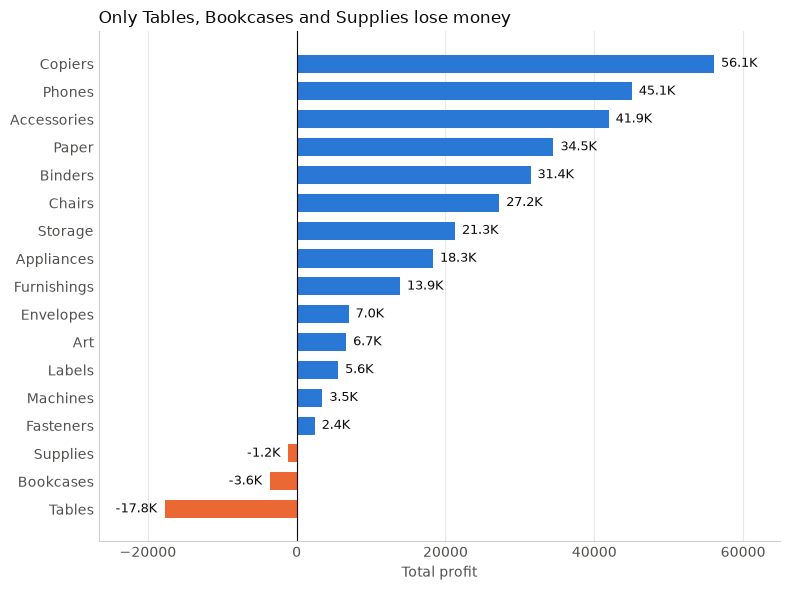

In [8]:
sub = df.groupby("sub_category").agg(sales=("sales", "sum"), profit=("profit", "sum"))
sub["margin"] = sub["profit"] / sub["sales"] * 100
sub = sub.sort_values("profit")
print(sub.round(2))   

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(sub.index, sub["profit"], height=0.65,
        color=[BLUE if p >= 0 else ORANGE for p in sub["profit"]])
ax.axvline(0, color=INK, linewidth=0.8)
for y, p in enumerate(sub["profit"]):
    ax.annotate(f"{p/1000:,.1f}K", (p, y), xytext=(5 if p >= 0 else -5, 0),
                textcoords="offset points", ha="left" if p >= 0 else "right",
                va="center", color=INK, fontsize=9)
ax.margins(x=0.12)
ax.set_xlabel("Total profit", color=MUTED)
ax.set_title("Only Tables, Bookcases and Supplies lose money", loc="left", color=INK)
style(ax)
ax.yaxis.grid(False)
ax.xaxis.grid(True, color="#e8e8e4", linewidth=0.8)
plt.tight_layout()
plt.savefig("../docs/images/profit_by_subcategory.png", dpi=200)
plt.show()

group     High    Low
region               
Central -40.57  24.75
East    -28.85  25.07
South   -35.18  22.31
West    -93.94  17.57


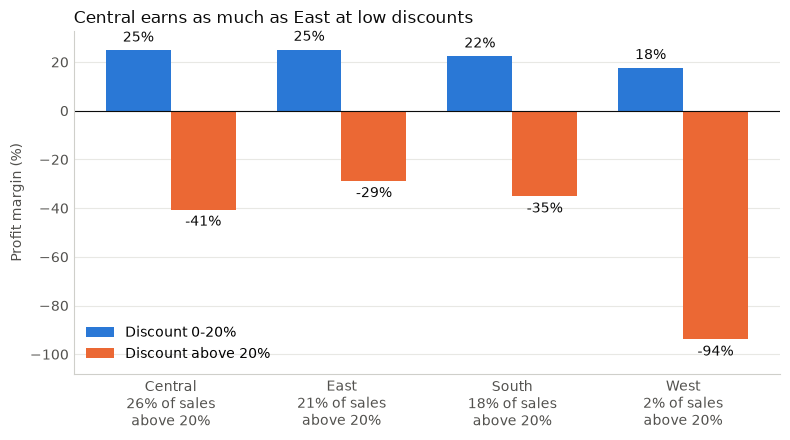

In [10]:
us = df[df["country_region"] == "United States"].copy()
us["group"] = np.where(us["discount"] > 0.20, "High", "Low")
r = us.groupby(["region", "group"]).agg(sales=("sales", "sum"), profit=("profit", "sum"))
r["margin"] = r["profit"] / r["sales"] * 100
regions = ["Central", "East", "South", "West"]
m = r["margin"].unstack("group").loc[regions]
print(m.round(2))   # must match SQL Query 08

tot = us.groupby("region")["sales"].sum()
hi = us[us["discount"] > 0.20].groupby("region")["sales"].sum()
share = (hi / tot * 100).loc[regions]

x = np.arange(len(regions)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
low = ax.bar(x - w/2, m["Low"], w, color=BLUE, label="Discount 0-20%")
high = ax.bar(x + w/2, m["High"], w, color=ORANGE, label="Discount above 20%")
ax.axhline(0, color=INK, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f"{reg}\n{s:.0f}% of sales above 20%" for reg, s in zip(regions, share)])
for bars in (low, high):
    for rect in bars:
        v = rect.get_height()
        ax.annotate(f"{v:.0f}%", (rect.get_x() + rect.get_width() / 2, v),
                    xytext=(0, 4 if v >= 0 else -4), textcoords="offset points",
                    ha="center", va="bottom" if v >= 0 else "top", color=INK)
ax.set_ylim(m.min().min() * 1.15, m.max().max() * 1.3)
ax.set_ylabel("Profit margin (%)", color=MUTED)
ax.set_title("Central earns as much as East at low discounts", loc="left", color=INK)
ax.legend(frameon=False)
style(ax)
ax.set_xticklabels([f"{reg}\n{s:.0f}% of sales\nabove 20%" for reg, s in zip(regions, share)])
plt.tight_layout()
plt.savefig("../docs/images/region_low_vs_high_discount.png", dpi=200)
plt.show()

In [5]:
df["high"] = df["discount"] > 0.2
print("rows with discount exactly 0.2:", (df["discount"] == 0.2).sum())
print("rows just above 0.2 (float noise?):", ((df["discount"] > 0.2) & (df["discount"] < 0.21)).sum())

four = ["Binders", "Machines", "Tables", "Bookcases"]
g = df[df["sub_category"].isin(four)].groupby(["sub_category", "high"])[["sales", "profit"]].sum()
g["margin_%"] = (g["profit"] / g["sales"] * 100).round(2)
print(g)

hi = df[df["high"]]
print("high-discount profit, all:", round(hi["profit"].sum(), 2), "rows:", len(hi))
print("high-discount profit, four sub-categories:", round(hi[hi["sub_category"].isin(four)]["profit"].sum(), 2))
print(hi.groupby("region").agg(rows=("profit", "size"), profit=("profit", "sum")).round(2))

rows with discount exactly 0.2: 3706
rows just above 0.2 (float noise?): 0
                          sales      profit  margin_%
sub_category high                                    
Binders      False  171160.4280  69988.3767     40.89
             True    36194.4530 -38562.2764   -106.54
Bookcases    False   86672.6175   7663.2914      8.84
             True    28688.5868 -11295.3650    -39.37
Machines     False  113085.9230  33017.3290     29.20
             True    76839.1080 -29555.3521    -38.46
Tables       False  117342.8120  13036.5267     11.11
             True    90677.3700 -30789.7328    -33.96
high-discount profit, all: -136020.69 rows: 1415
high-discount profit, four sub-categories: -110202.73
         rows    profit
region                 
Central   647 -52444.23
East      479 -42681.28
South     171 -24880.48
West      118 -16014.69


In [3]:
f = df[df["category"] == "Furniture"]
low = f[f["discount"] <= 0.2]
print(round(low["profit"].sum() / low["sales"].sum() * 100, 2))

13.38
